In [1]:
#Import Statements
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42

In [2]:
#Load the APPL dataset
DATA_PATH = Path("../data/raw/AAPL_daily_raw.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("data/raw/AAPL_daily_raw.csv")

df = pd.read_csv(DATA_PATH, index_col=0)

# Preserve the trading date shown in the CSV; remove timezone suffixes.
df.index = pd.to_datetime(
    df.index.astype(str).str.slice(0, 19),
    errors="raise"
)

df = df.sort_index()
df.index.name = "Date"

print("Shape:", df.shape)
print("Date range:", df.index.min().date(), "to", df.index.max().date())
print(df.head())

Shape: (2766, 9)
Date range: 2015-01-02 to 2025-12-31
                 Open       High        Low      Close  Adj Close     Volume  \
Date                                                                           
2015-01-02  27.847500  27.860001  26.837500  27.332500  24.171755  212818400   
2015-01-05  27.072500  27.162500  26.352501  26.562500  23.490799  257142000   
2015-01-06  26.635000  26.857500  26.157499  26.565001  23.493013  263188400   
2015-01-07  26.799999  27.049999  26.674999  26.937500  23.822430  160423600   
2015-01-08  27.307501  28.037500  27.174999  27.972500  24.737757  237458000   

            Dividends  Stock Splits  daily_return  
Date                                               
2015-01-02        0.0           0.0           NaN  
2015-01-05        0.0           0.0     -0.028172  
2015-01-06        0.0           0.0      0.000094  
2015-01-07        0.0           0.0      0.014022  
2015-01-08        0.0           0.0      0.038423  


In [3]:
#Builing Features and the Target
FEATURES = [
    "return_1d",
    "return_5d",
    "return_10d",
    "price_to_sma20",
    "price_to_sma50",
    "volatility_20d",
    "momentum_10d",
    "relative_volume",
]

df["return_1d"] = df["Adj Close"].pct_change(1)
df["return_5d"] = df["Adj Close"].pct_change(5)
df["return_10d"] = df["Adj Close"].pct_change(10)

df["sma20"] = df["Adj Close"].rolling(20).mean()
df["sma50"] = df["Adj Close"].rolling(50).mean()

df["price_to_sma20"] = df["Adj Close"] / df["sma20"] - 1
df["price_to_sma50"] = df["Adj Close"] / df["sma50"] - 1

df["volatility_20d"] = df["return_1d"].rolling(20).std()
df["momentum_10d"] = df["Adj Close"].pct_change(10)

df["relative_volume"] = (
    df["Volume"] / df["Volume"].rolling(20).mean()
)

df["future_return_1d"] = (
    df["Adj Close"].shift(-1) / df["Adj Close"] - 1
)

df["target_up"] = (df["future_return_1d"] > 0).astype(int)

model_df = df[
    FEATURES + ["future_return_1d", "target_up"]
].dropna().copy()

X = model_df[FEATURES]
y = model_df["target_up"]

print("Model rows:", len(model_df))
print("\nTarget distribution:")
print(y.value_counts().rename(index={0: "DOWN", 1: "UP"}))
print("\nFeature missing values:")
print(X.isna().sum())

Model rows: 2716

Target distribution:
target_up
UP      1438
DOWN    1278
Name: count, dtype: int64

Feature missing values:
return_1d          0
return_5d          0
return_10d         0
price_to_sma20     0
price_to_sma50     0
volatility_20d     0
momentum_10d       0
relative_volume    0
dtype: int64


In [4]:
#Chronologically Splitting the data
n = len(model_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_idx = np.arange(0, train_end - 1)
val_idx = np.arange(train_end, val_end - 1)
test_idx = np.arange(val_end, n)

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

for name, X_part, y_part in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test),
]:
    print(
        f"{name}: {X_part.index.min().date()} to "
        f"{X_part.index.max().date()} | rows={len(X_part)}"
    )

assert X_train.index.max() < X_val.index.min()
assert X_val.index.max() < X_test.index.min()

Train: 2015-03-16 to 2022-09-28 | rows=1900
Validation: 2022-09-30 to 2024-05-13 | rows=406
Test: 2024-05-15 to 2025-12-30 | rows=408


In [5]:
#Building a reusable evaluation Function
def evaluate_classifier(model, X_part, y_part):
    predictions = model.predict(X_part)

    results = {
        "accuracy": accuracy_score(y_part, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_part, predictions
        ),
        "macro_f1": f1_score(
            y_part, predictions, average="macro", zero_division=0
        ),
    }

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_part)[:, 1]
        results["roc_auc"] = roc_auc_score(y_part, probabilities)
    else:
        results["roc_auc"] = np.nan

    return results

In [ ]:
#Training Four Models - Majority Baseline, Logistic Regression, Decision Tree, Random Forest
models = {
    "Majority baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            C=1.0,
            max_iter=2000,
            random_state=RANDOM_STATE
        )),
    ]),

    "Decision tree": DecisionTreeClassifier(
        max_depth=3,
        min_samples_leaf=20,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_features="sqrt",
        max_depth=None,
        min_samples_leaf=20,
        min_samples_split=40,
        bootstrap=True,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Trained: {name}")

Trained: Majority baseline
Trained: Logistic regression
Trained: Decision tree
Trained: Random Forest


In [ ]:
#Compare Training and validation performance
rows = []

for name, model in models.items():
    train_scores = evaluate_classifier(model, X_train, y_train)
    val_scores = evaluate_classifier(model, X_val, y_val)

    rows.append({
        "model": name,
        "train_balanced_accuracy": train_scores["balanced_accuracy"],
        "val_balanced_accuracy": val_scores["balanced_accuracy"],
        "train_macro_f1": train_scores["macro_f1"],
        "val_macro_f1": val_scores["macro_f1"],
        "val_roc_auc": val_scores["roc_auc"],
    })

comparison = pd.DataFrame(rows).set_index("model")

comparison["balanced_accuracy_gap"] = (
    comparison["train_balanced_accuracy"]
    - comparison["val_balanced_accuracy"]
)

comparison = comparison.sort_values(
    ["val_balanced_accuracy", "val_macro_f1"],
    ascending=False
)

comparison.round(4)

,train_balanced_accuracy,val_balanced_accuracy,train_macro_f1,val_macro_f1,val_roc_auc,balanced_accuracy_gap
model,,,,,,
Decision tree,0.5518,0.5185,0.5112,0.4691,0.5240,0.0333
Majority baseline,0.5000,0.5000,0.3439,0.3409,0.5000,0.0000
Logistic regression,0.5266,0.4835,0.4835,0.4236,0.4433,0.0431
Random Forest,0.7471,0.4772,0.7466,0.4660,0.4960,0.2699


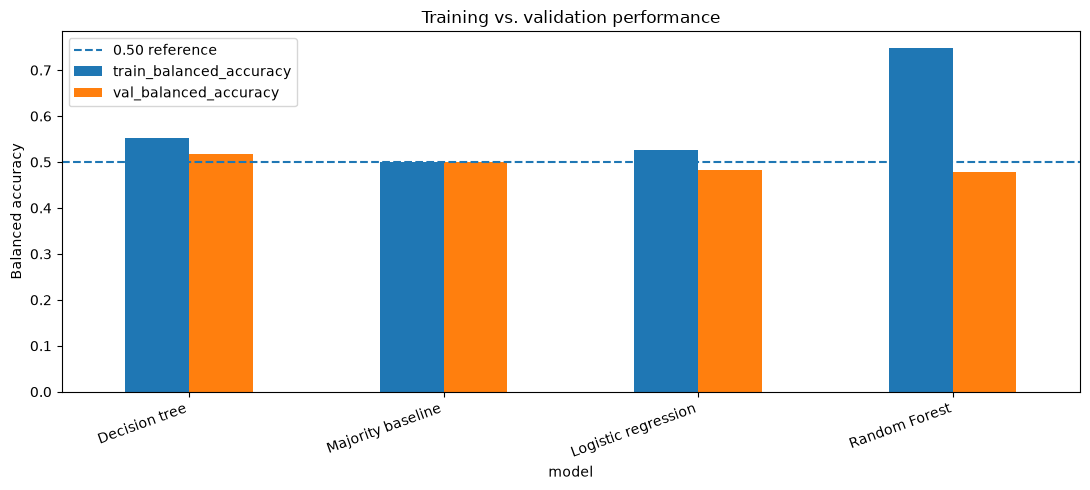

In [8]:
#Visualizing the training-validation gap
plot_data = comparison[
    ["train_balanced_accuracy", "val_balanced_accuracy"]
]

plot_data.plot(kind="bar", figsize=(11, 5))
plt.axhline(
    0.5,
    linestyle="--",
    label="0.50 reference"
)
plt.ylabel("Balanced accuracy")
plt.title("Training vs. validation performance")
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

return_1d          0.1485
price_to_sma20     0.1384
volatility_20d     0.1273
price_to_sma50     0.1204
relative_volume    0.1193
return_5d          0.1177
return_10d         0.1156
momentum_10d       0.1128
Name: impurity_importance, dtype: float64


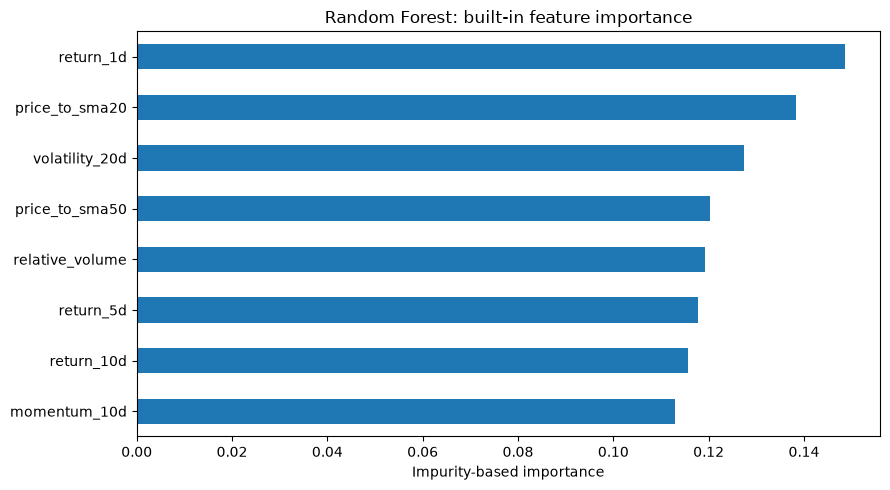

In [10]:
#Visualizing Random Forest Built-in Feature Importance
rf = models["Random Forest"]

impurity_importance = pd.Series(
    rf.feature_importances_,
    index=FEATURES,
    name="impurity_importance"
).sort_values(ascending=False)

print(impurity_importance.round(4))

impurity_importance.sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)
plt.xlabel("Impurity-based importance")
plt.title("Random Forest: built-in feature importance")
plt.tight_layout()
plt.show()

In [11]:
#Permutation Importance on Validation data
perm_result = permutation_importance(
    rf,
    X_val,
    y_val,
    scoring="balanced_accuracy",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "feature": FEATURES,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std,
}).sort_values("importance_mean", ascending=False)

permutation_df.round(4)

,feature,importance_mean,importance_std
5,volatility_20d,-0.0065,0.0152
7,relative_volume,-0.0128,0.0090
4,price_to_sma50,-0.0162,0.0083
2,return_10d,-0.0243,0.0096
1,return_5d,-0.0263,0.0111
0,return_1d,-0.0277,0.0197
6,momentum_10d,-0.0308,0.0052
3,price_to_sma20,-0.0365,0.0104


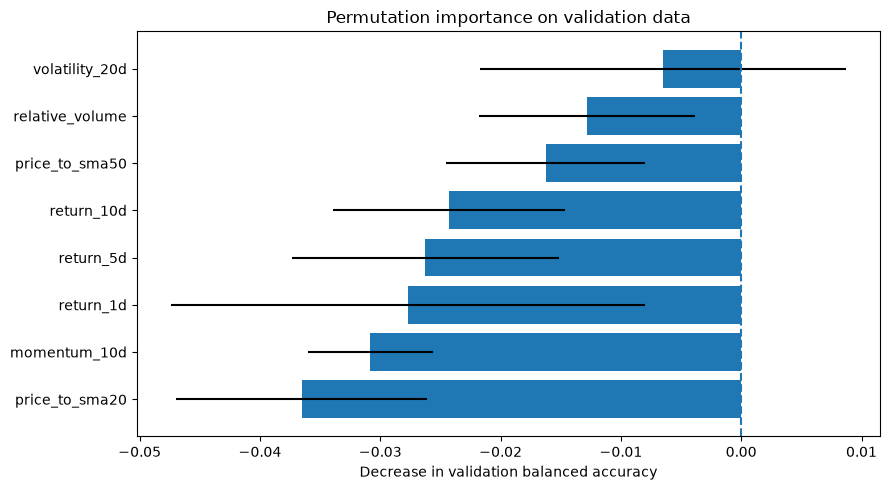

In [12]:
#Plotting permutation importance
plot_df = permutation_df.sort_values("importance_mean")

plt.figure(figsize=(9, 5))
plt.barh(
    plot_df["feature"],
    plot_df["importance_mean"],
    xerr=plot_df["importance_std"]
)
plt.axvline(0, linestyle="--")
plt.xlabel("Decrease in validation balanced accuracy")
plt.title("Permutation importance on validation data")
plt.tight_layout()
plt.show()

In [13]:
#Compare two Importance Models
importance_comparison = (
    pd.DataFrame({
        "impurity_importance": rf.feature_importances_,
        "permutation_importance": perm_result.importances_mean,
    }, index=FEATURES)
    .sort_values("permutation_importance", ascending=False)
)

importance_comparison.round(4)

,impurity_importance,permutation_importance
volatility_20d,0.1273,-0.0065
relative_volume,0.1193,-0.0128
price_to_sma50,0.1204,-0.0162
return_10d,0.1156,-0.0243
return_5d,0.1177,-0.0263
return_1d,0.1485,-0.0277
momentum_10d,0.1128,-0.0308
price_to_sma20,0.1384,-0.0365


In [16]:
#Choosing validation scores
validation_rows = []

for name, model in models.items():
    scores = evaluate_classifier(model, X_val, y_val)
    validation_rows.append({
        "model": name,
        **scores
    })

validation_results = (
    pd.DataFrame(validation_rows)
    .set_index("model")
    .sort_values(
        ["balanced_accuracy", "macro_f1"],
        ascending=False
    )
)

validation_results.round(4)

,accuracy,balanced_accuracy,macro_f1,roc_auc
model,,,,
Decision tree,0.5296,0.5185,0.4691,0.5240
Majority baseline,0.5172,0.5000,0.3409,0.5000
Logistic regression,0.4951,0.4835,0.4236,0.4433
Random Forest,0.4828,0.4772,0.4660,0.4960


In [17]:
#Selecting the best model among the four models
best_model_name = validation_results.index[0]
best_model = models[best_model_name]

print("Selected using validation data:", best_model_name)

Selected using validation data: Decision tree


In [18]:
#Evaluate the selected model on test data
test_scores = evaluate_classifier(
    best_model,
    X_test,
    y_test
)

print("Selected model:", best_model_name)
print(pd.Series(test_scores).round(4))

Selected model: Decision tree
accuracy             0.5417
balanced_accuracy    0.4975
macro_f1             0.4546
roc_auc              0.4980
dtype: float64


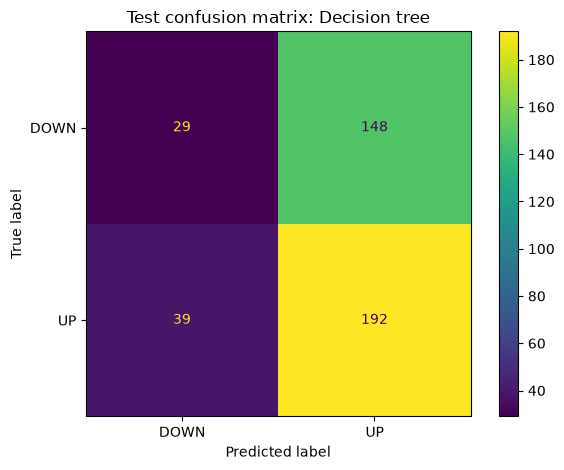

              precision    recall  f1-score   support

        DOWN       0.43      0.16      0.24       177
          UP       0.56      0.83      0.67       231

    accuracy                           0.54       408
   macro avg       0.50      0.50      0.45       408
weighted avg       0.50      0.54      0.48       408



In [19]:
#Confusion matrix
test_predictions = best_model.predict(X_test)

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        y_test,
        test_predictions,
        labels=[0, 1]
    ),
    display_labels=["DOWN", "UP"]
).plot()

plt.title(f"Test confusion matrix: {best_model_name}")
plt.tight_layout()
plt.show()

print(
    classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=["DOWN", "UP"],
        zero_division=0
    )
)